In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('payments.csv')
df = df.rename(columns={'default payment next month': 'default'})
df = df.drop(columns=['ID'])

print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [2]:
df.info()
print(df.isnull().sum().sum(), "missing value")
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   30000 non-nu

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


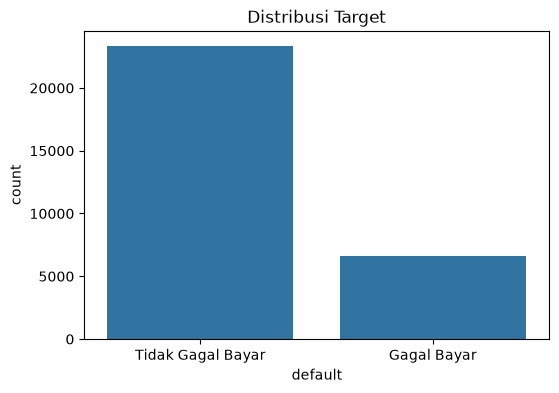

default
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [3]:
plt.figure(figsize=(6,4))
sns.countplot(x='default', data=df)
plt.xticks([0,1], ['Tidak Gagal Bayar','Gagal Bayar'])
plt.title('Distribusi Target')
plt.show()
print(df['default'].value_counts(normalize=True))

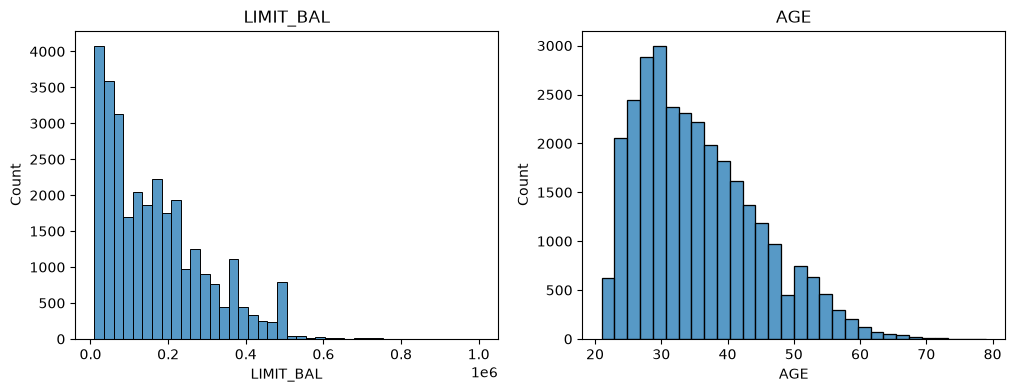

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df['LIMIT_BAL'], bins=40, ax=ax[0]); ax[0].set_title('LIMIT_BAL')
sns.histplot(df['AGE'], bins=30, ax=ax[1]); ax[1].set_title('AGE')
plt.show()

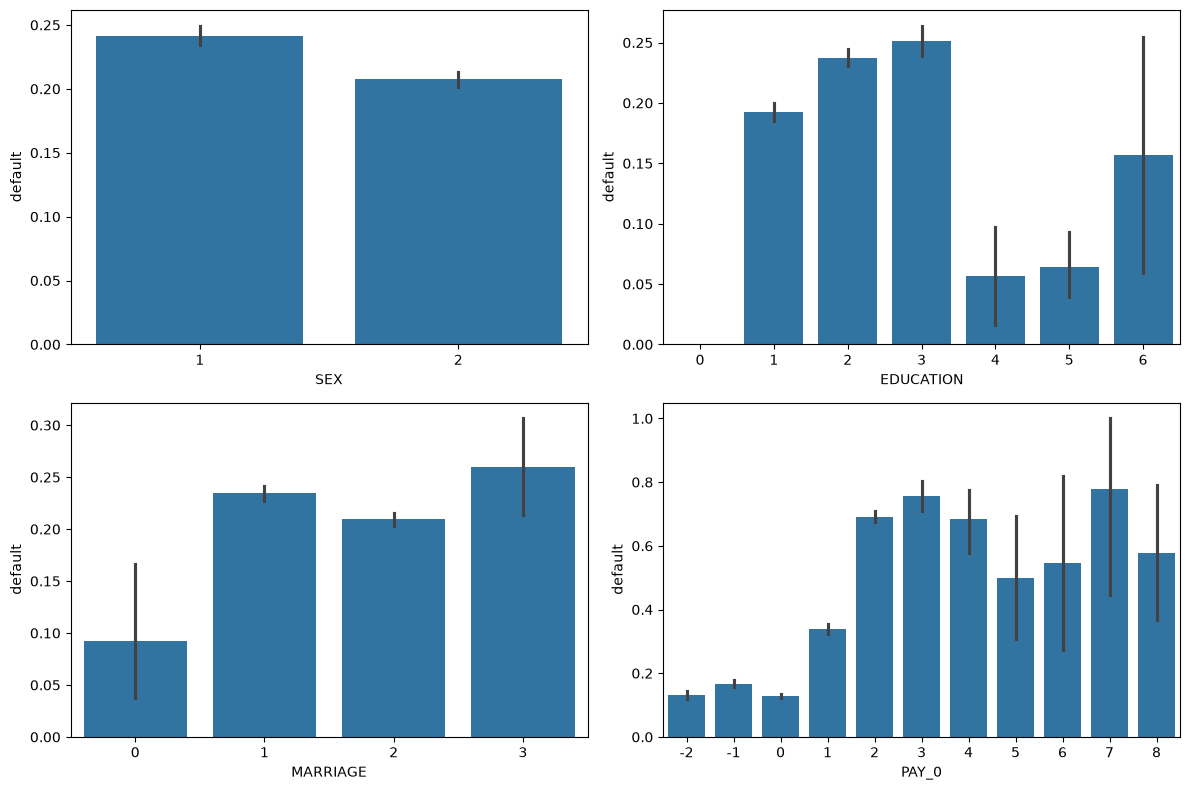

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(12,8))
sns.barplot(x='SEX', y='default', data=df, ax=ax[0,0])
sns.barplot(x='EDUCATION', y='default', data=df, ax=ax[0,1])
sns.barplot(x='MARRIAGE', y='default', data=df, ax=ax[1,0])
sns.barplot(x='PAY_0', y='default', data=df, ax=ax[1,1])
plt.tight_layout(); plt.show()

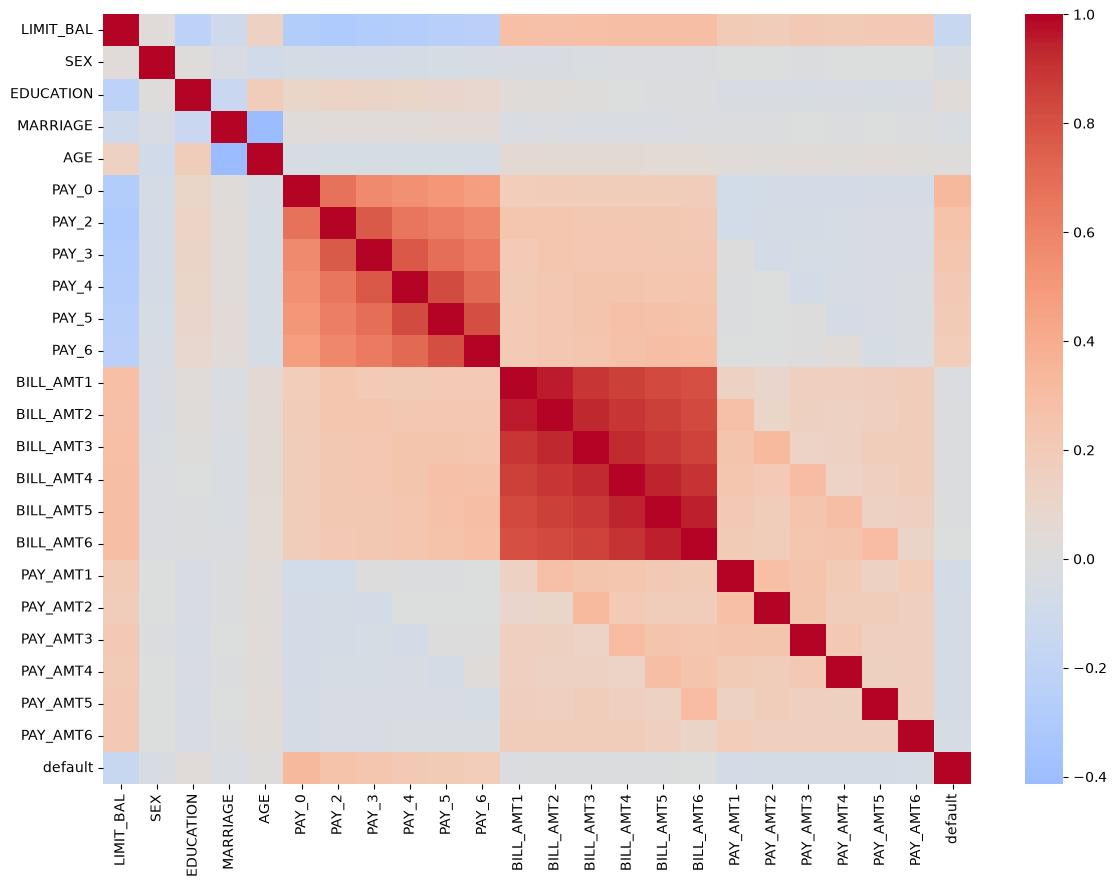

In [6]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.show()

In [7]:
df['EDUCATION'] = df['EDUCATION'].replace({0:4, 5:4, 6:4})
df['MARRIAGE'] = df['MARRIAGE'].replace({0:3})

# One-hot encoding (konversi kategorikal -> numerik)
df = pd.get_dummies(df, columns=['SEX','EDUCATION','MARRIAGE'], drop_first=True, dtype=int)
df.head()

,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,...,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
0,20000,24,2,2,-1,-1,-2,-2,3913,3102,...,0,0,0,1,1,1,0,0,0,0
1,120000,26,-1,2,0,0,0,2,2682,1725,...,1000,0,2000,1,1,1,0,0,1,0
2,90000,34,0,0,0,0,0,0,29239,14027,...,1000,1000,5000,0,1,1,0,0,1,0
3,50000,37,0,0,0,0,0,0,46990,48233,...,1100,1069,1000,0,1,1,0,0,0,0
4,50000,57,-1,0,-1,0,0,0,8617,5670,...,9000,689,679,0,0,1,0,0,0,0


In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['default'])
y = df['default']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [9]:
from sklearn.preprocessing import StandardScaler

num_cols = ['LIMIT_BAL','AGE'] + \
    [c for c in X.columns if c.startswith(('PAY_','BILL_AMT'))]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])   # transform saja!

In [10]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print(y_train_res.value_counts())

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_res, y_train_res)

default
0    18691
1    18691
Name: count, dtype: int64


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

              precision    recall  f1-score   support

           0       0.86      0.69      0.77      4673
           1       0.36      0.61      0.45      1327

    accuracy                           0.67      6000
   macro avg       0.61      0.65      0.61      6000
weighted avg       0.75      0.67      0.70      6000



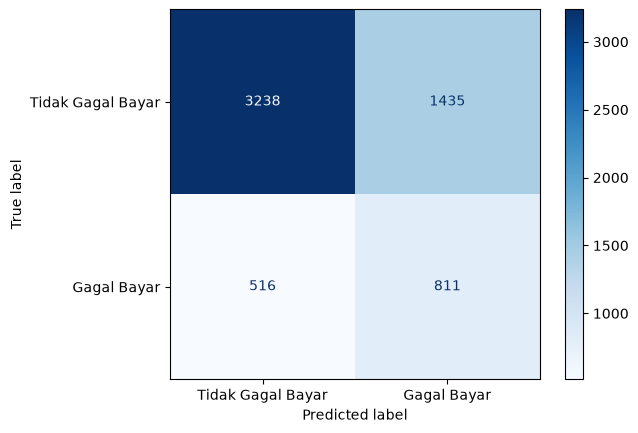

In [11]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)

pred = model.predict(X_test)
print(classification_report(y_test, pred))

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['Tidak Gagal Bayar','Gagal Bayar']).plot(cmap='Blues')
plt.show()

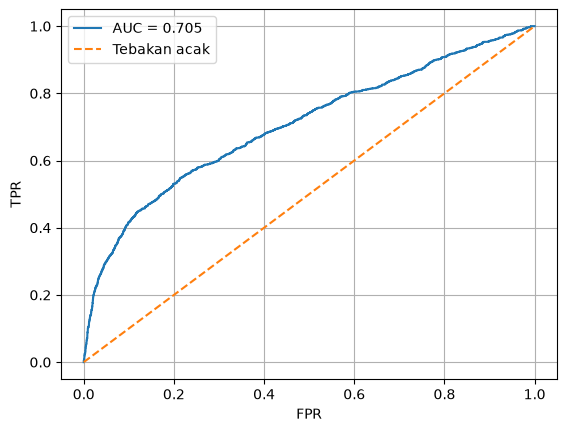

In [12]:
proba = model.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0,1],[0,1],'--', label='Tebakan acak')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.grid(True)
plt.show()

In [15]:
import json
import sys
from datetime import datetime
from importlib import metadata
 
import joblib
import sklearn
 
joblib.dump(model, "model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "columns.pkl")
joblib.dump(num_cols, "num_cols.pkl")
 
# requirements.txt dengan versi terkunci
paket = ["flask", "gunicorn", "scikit-learn", "pandas", "numpy", "joblib"]
baris = []
for nama in paket:
    try:
        baris.append(f"{nama}=={metadata.version(nama)}")
    except metadata.PackageNotFoundError:
        print(f"PERINGATAN: paket '{nama}' belum terpasang di kernel ini. "
              f"Jalankan: pip install {nama}")
with open("requirements.txt", "w") as f:
    f.write("\n".join(baris) + "\n")
 
# Versi Python untuk Render (.python-version)
with open(".python-version", "w") as f:
    f.write(f"{sys.version_info.major}.{sys.version_info.minor}\n")
 
# Catatan versi yang dipakai app.py untuk memberi peringatan bila tidak cocok
with open("model_info.json", "w") as f:
    json.dump({
        "scikit_learn": sklearn.__version__,
        "python": f"{sys.version_info.major}.{sys.version_info.minor}",
        "n_features": len(X.columns),
        "saved_at": datetime.now().isoformat(timespec="seconds"),
    }, f, indent=2)
 
print("Tersimpan: model.pkl, scaler.pkl, columns.pkl, num_cols.pkl")
print("Dibuat   : requirements.txt, .python-version, model_info.json")
print("\nIsi requirements.txt:")
print(open("requirements.txt").read())

Tersimpan: model.pkl, scaler.pkl, columns.pkl, num_cols.pkl
Dibuat   : requirements.txt, .python-version, model_info.json

Isi requirements.txt:
flask==3.1.3
gunicorn==26.2.0
scikit-learn==1.9.1
pandas==3.0.6
numpy==2.4.6
joblib==1.6.0

